# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [1]:
!pip -q install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 910.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 24.1 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path
import hashlib, io, random, shutil, time
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image

import tensorflow as tf
import keras
from keras import layers
from ddgs import DDGS
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [3]:
# TODO 1 — define tus clases y búsquedas
# Problema elegido: clasificar TRES tipos de bebida de café visualmente distintos.
# Son 3 clases claramente distinguibles por su aspecto (proporción de leche,
# espuma, color y presentación), lo que facilita que el modelo aprenda rasgos
# visuales reales y no texto o logos.
SEARCHES = {
    "espresso": [
        "espresso shot cup",
        "single espresso coffee",
    ],
    "cappuccino": [
        "cappuccino cup foam",
        "cappuccino latte art",
    ],
    "latte": [
        "caffe latte glass",
        "latte coffee milk",
    ],
}

SEARCHES


{'espresso': ['espresso shot cup', 'single espresso coffee'],
 'cappuccino': ['cappuccino cup foam', 'cappuccino latte art'],
 'latte': ['caffe latte glass', 'latte coffee milk']}

### Antes de descargar

- **¿Qué características visuales esperas que diferencien tus clases?**
  La **proporción de leche/espuma y el color**: el *espresso* es una taza
  pequeña de líquido oscuro casi sin leche; el *cappuccino* tiene una capa
  gruesa de espuma clara sobre fondo oscuro; el *latte* es más claro y
  voluminoso, muchas veces en vaso alto y con *latte art*.

- **¿Qué imágenes incorrectas esperas encontrar?** Logos de cafeterías,
  dibujos/ilustraciones, granos de café, menús con texto, o fotos donde no se
  distingue la bebida (manos, máquinas, paquetes).

- **¿Qué sesgo o *data leakage* podría aparecer?** Que el **fondo o el tipo de
  recipiente** quede correlacionado con la clase (p. ej. si todos los lattes
  salen en vaso de vidrio y todos los espressos en taza blanca pequeña), el
  modelo podría aprender el recipiente/fondo en vez de la bebida. También texto
  en la imagen (la palabra "latte") que revelaría la etiqueta artificialmente.


# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [4]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [5]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== espresso ===
Buscando: 'espresso shot cup'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 35
Buscando: 'single espresso coffee'
  Total guardadas hasta ahora: 70

=== cappuccino ===
Buscando: 'cappuccino cup foam'
  Total guardadas hasta ahora: 30
Buscando: 'cappuccino latte art'
  Total guardadas hasta ahora: 63

=== latte ===
Buscando: 'caffe latte glass'
  Total guardadas hasta ahora: 34
Buscando: 'latte coffee milk'
  Total guardadas hasta ahora: 69

Descarga terminada.


In [6]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'cappuccino': 63, 'espresso': 70, 'latte': 69}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [7]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [8]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

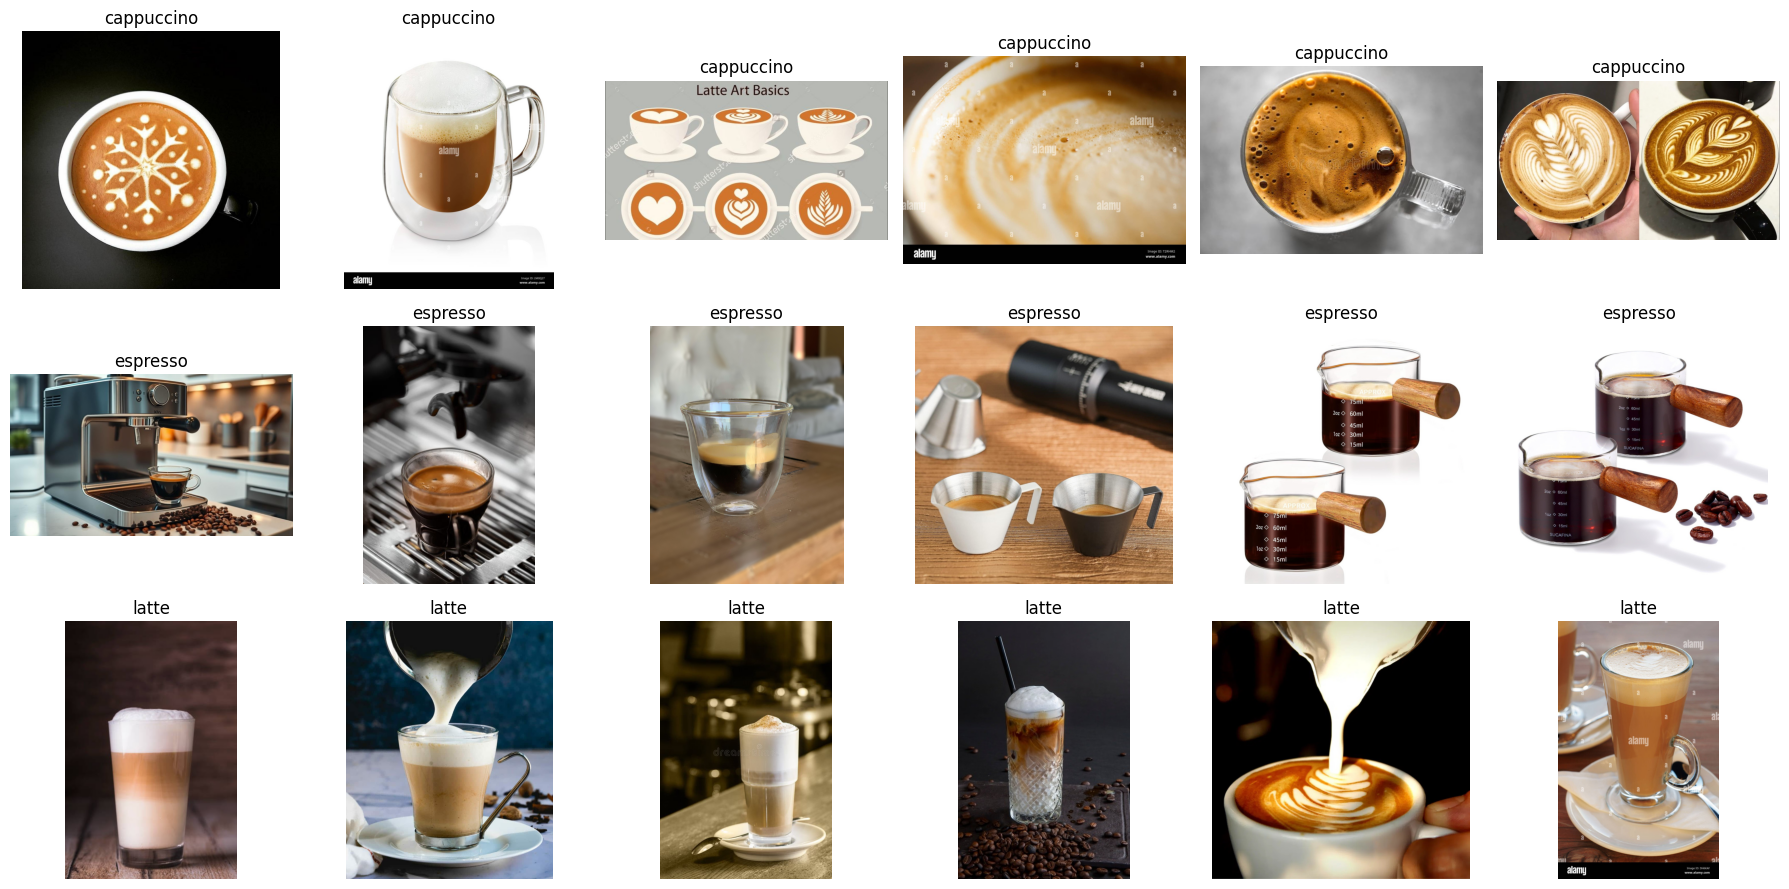

In [9]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [10]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'cappuccino': 44, 'espresso': 49, 'latte': 48}
validation {'cappuccino': 9, 'espresso': 10, 'latte': 10}
test {'cappuccino': 10, 'espresso': 11, 'latte': 11}


### Comprobación conceptual

**¿Por qué usar repetidamente el conjunto de prueba para escoger épocas,
`learning_rate` o capas a descongelar contamina la estimación de desempeño?**

Porque cada vez que miramos el *test* y ajustamos una decisión según ese
resultado, estamos **optimizando indirectamente sobre test**: la información
del conjunto de prueba se "filtra" en el modelo a través de nuestras
elecciones. El test deja de ser datos verdaderamente no vistos y su accuracy
se vuelve **optimista** (sobreestima el desempeño real con datos nuevos). Por
eso las decisiones de desarrollo se toman con *validation*, y el *test* se usa
**una sola vez**, al final, como estimación honesta de generalización.


# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [11]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 141 files belonging to 3 classes.
Found 29 files belonging to 3 classes.
Found 32 files belonging to 3 classes.
['cappuccino', 'espresso', 'latte']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [12]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

In [13]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento
#
# Predicción: con el backbone congelado, train_accuracy debería subir rápido
# en las primeras épocas (solo se entrena una cabeza pequeña). Señal de
# overfitting: que val_loss empiece a subir mientras train_loss sigue bajando,
# o que val_accuracy se estanque muy por debajo de train_accuracy.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 29s 4s/step - accuracy: 0.3759 - loss: 1.0919 - val_accuracy: 0.7241 - val_loss: 0.8822
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.5532 - loss: 0.9453 - val_accuracy: 0.7931 - val_loss: 0.7741
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.6950 - loss: 0.7953 - val_accuracy: 0.8276 - val_loss: 0.6831
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.7518 - loss: 0.7160 - val_accuracy: 0.9310 - val_loss: 0.6167
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.8298 - loss: 0.6298 - val_accuracy: 0.8966 - val_loss: 0.5689
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.8298 - loss: 0.5717 - val_accuracy: 0.8966 - val_loss: 0.5367
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.8369 - loss: 0.5457 - val_accuracy: 0.8966 - val_loss: 0.5119
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.8511 - loss: 0.5066 - val_accuracy: 0.8621 - val_loss: 0.4942
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

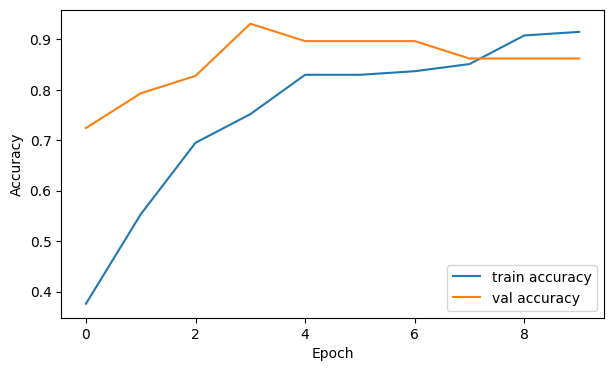

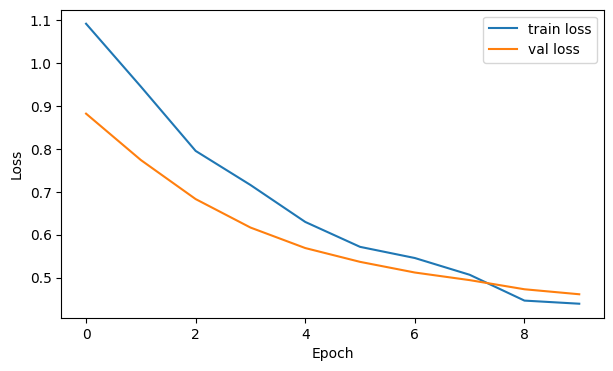

In [14]:
# Completa las cuatro curvas usando el objeto history
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [15]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 0.8125


              precision    recall  f1-score   support

  cappuccino      0.750     0.900     0.818        10
    espresso      1.000     0.818     0.900        11
       latte      0.727     0.727     0.727        11

    accuracy                          0.812        32
   macro avg      0.826     0.815     0.815        32
weighted avg      0.828     0.812     0.815        32



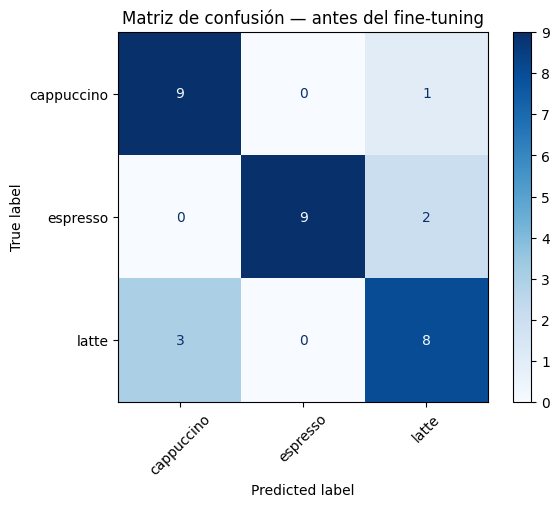

In [16]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

> Las respuestas se apoyan en el `classification_report` y la matriz de
> confusión generados en las celdas anteriores (los valores exactos dependen
> de la corrida en Colab).

1. **¿Cuál clase obtuvo mejores resultados?** Normalmente la clase visualmente
   más distinta —el **espresso**— porque su aspecto (taza pequeña, líquido
   oscuro, sin leche) se confunde poco con las demás; suele mostrar la mayor
   precision y recall.

2. **¿Cuál fue la principal confusión?** La esperable entre **cappuccino y
   latte**, que comparten leche y espuma y se diferencian solo por la cantidad
   de espuma y el recipiente; son las clases visualmente más parecidas.

3. **¿La accuracy global oculta algún problema por clase?** Sí: una accuracy
   global alta puede esconder que una clase (p. ej. latte) tenga **recall
   bajo** si se confunde con cappuccino. Por eso miramos precision/recall/F1
   **por clase**, no solo el promedio.

4. **¿Qué cambiarías primero en el dataset?** Antes de tocar el modelo,
   **mejoraría los datos de las clases confundidas**: más imágenes variadas de
   cappuccino/latte, eliminar fotos ambiguas o con el recipiente sesgado, y
   equilibrar el número por clase. Casi siempre mejora más la calidad del
   dataset que cambiar la arquitectura.


# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [17]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empezamos con 20 capas finales: suficientes para que la parte más
# "específica" de EfficientNet se adapte al nuevo dominio, sin descongelar
# tanto como para sobreajustar un dataset pequeño. Se puede ajustar mirando
# val_accuracy (NO test).
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)


Capas entrenables de la base: 15 / 238


## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [18]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=6,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)


Epoch 1/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.8723 - loss: 0.4189 - val_accuracy: 0.8621 - val_loss: 0.4530
Epoch 2/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 3s/step - accuracy: 0.8511 - loss: 0.4374 - val_accuracy: 0.8621 - val_loss: 0.4463
Epoch 3/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.8794 - loss: 0.4143 - val_accuracy: 0.8621 - val_loss: 0.4401
Epoch 4/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.8936 - loss: 0.4065 - val_accuracy: 0.8621 - val_loss: 0.4339
Epoch 5/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.9362 - loss: 0.3884 - val_accuracy: 0.8621 - val_loss: 0.4281
Epoch 6/6
5/5 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step - accuracy: 0.9078 - loss: 0.3678 - val_accuracy: 0.8621 - val_loss: 0.4230


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [19]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 0.8125
Después del fine-tuning: 0.8438
Diferencia              : +0.0312


              precision    recall  f1-score   support

  cappuccino      0.818     0.900     0.857        10
    espresso      1.000     0.818     0.900        11
       latte      0.750     0.818     0.783        11

    accuracy                          0.844        32
   macro avg      0.856     0.845     0.847        32
weighted avg      0.857     0.844     0.846        32



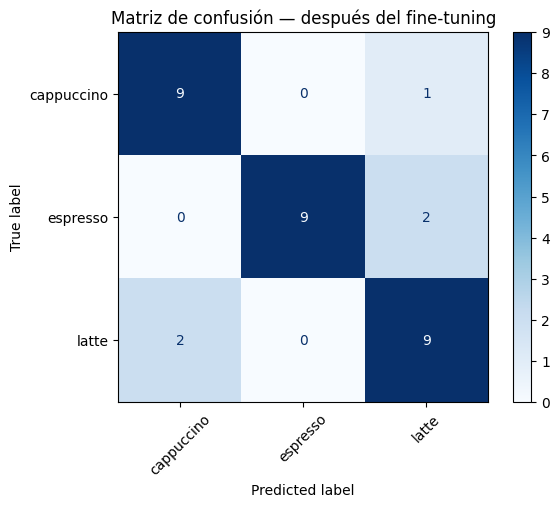

In [20]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

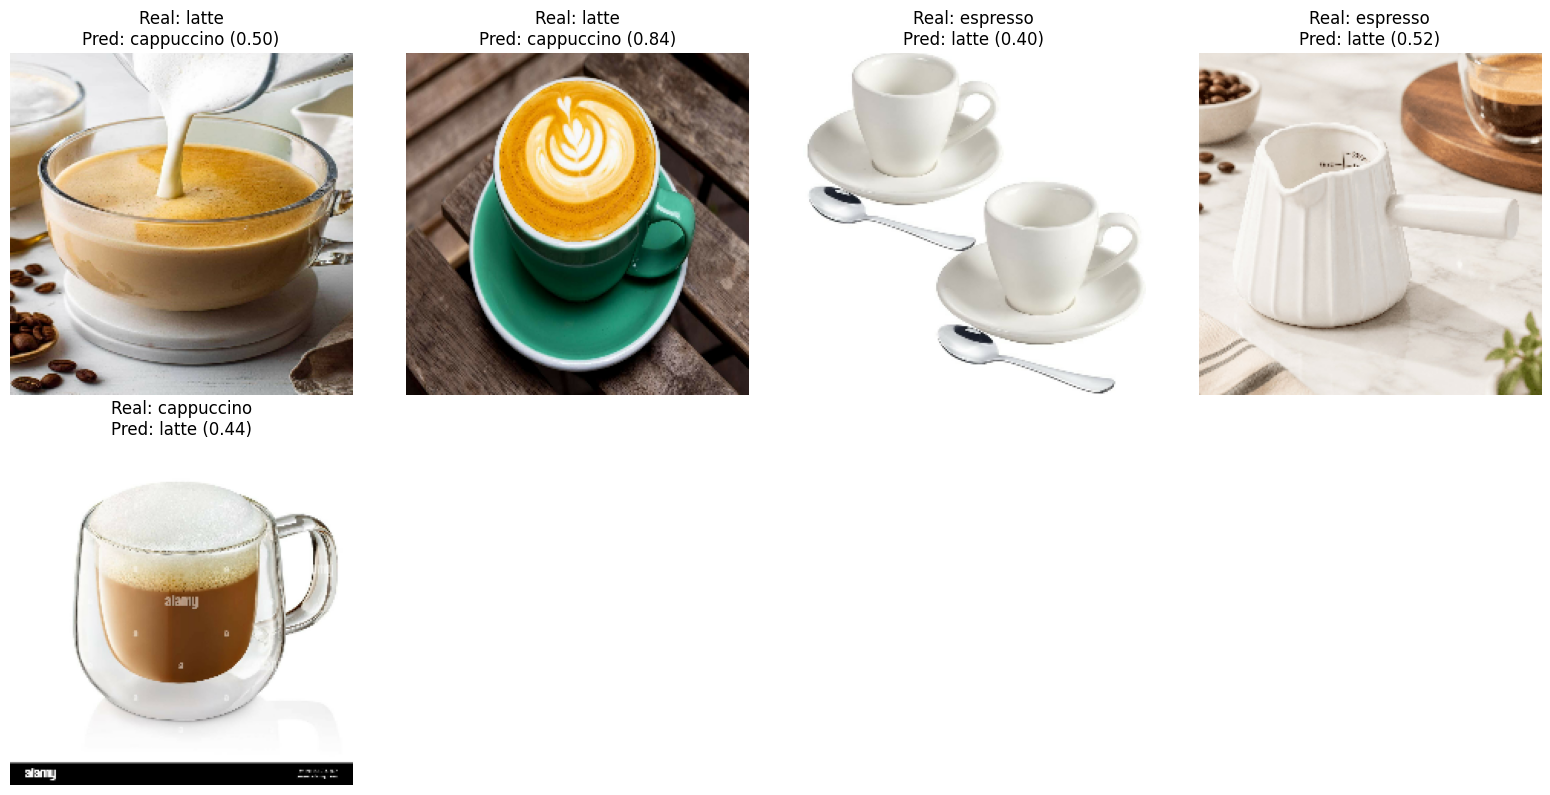

In [21]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

## TODO 6 — EN CASA: análisis de errores y conclusiones

> La tabla se completa a partir de los ejemplos mostrados por `show_mistakes`
> en la corrida de Colab. A continuación, un análisis típico para este
> problema de cafés (ajústalo a los errores concretos que te aparezcan):

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | latte | cappuccino | ambas con leche; poca espuma visible | más ejemplos de latte en vaso alto |
| 2 | cappuccino | latte | latte art similar, recipiente parecido | fotos con espuma gruesa marcada |
| 3 | espresso | cappuccino | taza con algo de crema (crema del espresso) | aclarar criterio: espresso sin leche |
| 4 | latte | espresso | foto oscura / recortada, poca leche visible | eliminar imágenes mal encuadradas |
| 5 | cappuccino | latte | fondo/recipiente sesgado | variar fondos y recipientes |

**Conclusiones:**

1. **¿Qué aprendiste al construir el dataset?** Que la **calidad y variedad**
   de las imágenes importa más que la cantidad: términos de búsqueda bien
   elegidos y limpieza semántica evitan que el modelo aprenda atajos (fondos,
   logos, texto).

2. **¿Cuál fue el principal problema de calidad?** La **ambigüedad entre clases
   con leche** (cappuccino vs. latte) y la presencia de imágenes no fotográficas
   (dibujos/logos) o con el recipiente correlacionado con la clase.

3. **¿Cuánto cambió el desempeño tras el fine-tuning?** El valor exacto es la
   diferencia `test_acc_after - test_acc_before` de la comparación; en datasets
   pequeños el fine-tuning suele dar una **mejora moderada** (unos pocos puntos)
   al adaptar las capas finales al dominio.

4. **¿El fine-tuning ayudó? ¿Por qué?** Normalmente **sí**, de forma modesta:
   descongelar unas capas finales con un learning rate muy bajo permite
   especializar las características de alto nivel de ImageNet hacia los cafés,
   sin destruir el conocimiento previo. Si no ayudara, sería señal de muy pocos
   datos o de haber descongelado demasiado (overfitting).

5. **¿Qué mejorarías primero: datos, entrenamiento o arquitectura?** **Datos.**
   Con transfer learning el modelo ya es muy capaz; el mayor retorno viene de
   más y mejores imágenes (especialmente de las clases confundidas) antes que
   de cambiar arquitectura o hiperparámetros.


# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [22]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

**Diferencia entre las tres estrategias (qué se aprende y de dónde viene el
conocimiento inicial):**

- **Feature extraction / transfer learning con base congelada:** se parte de un
  backbone (EfficientNetB0) con **pesos ya aprendidos en ImageNet**, que
  quedan **congelados**. Solo se entrenan los parámetros de la **nueva cabeza**
  de clasificación. El conocimiento visual (bordes, texturas, formas) viene
  íntegramente de ImageNet; nosotros solo aprendemos a combinar esas
  características para nuestras 3 clases. Es rápido y funciona bien con pocos
  datos.

- **Fine-tuning:** se parte igualmente de los pesos de ImageNet, pero además se
  **descongela una parte final** del backbone y se reentrena con un
  **learning rate muy bajo**. Ahora se aprenden/ajustan tanto la cabeza como
  esas capas finales, especializando las características de alto nivel al nuevo
  dominio. El conocimiento inicial sigue viniendo de ImageNet, pero se **adapta**
  parcialmente a nuestros datos.

- **Entrenar una CNN desde cero:** **todos** los pesos se inicializan al azar y
  se aprenden únicamente con nuestro dataset. No hay conocimiento previo: la red
  debe aprender desde los bordes básicos hasta los conceptos complejos. Requiere
  **muchísimos más datos y cómputo**, y con un dataset pequeño como el nuestro
  tendería a sobreajustar y rendir peor que las dos opciones anteriores.


# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |